## 1. Question and data

Can passive underwater sound detect and classify vessel activity when labels come from AIS tracking and multiple vessels may overlap acoustically?

Use the frozen representative_v2 development protocol: training on May 16-27, 2025, and validation on May 28-June 2. Compare the same 11 audio features and logistic regression with a training-label-frequency dummy for binary presence, primary type, and multilabel class presence. No tuning or test evaluation.

Natural validation is the main benchmark of readable, eligible windows. The disjoint coverage supplement is enriched and reported separately, not pooled into headline scores. Validate exact exported membership and global WAV/day split assignments before reading development audio. Test membership and dates are checked using identifiers only; test labels and audio are not evaluated. Run preparation first, then run this notebook from the top.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from scipy.signal import welch
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if root.name == 'research':
    root = root.parent
data = root / 'data'
audio_dir = data / 'PORTIA_Clean_Release' / 'audio'
classes = ['tug', 'pilot', 'cargo', 'passenger', 'support', 'tanker', 'other']
pilot = pd.read_csv(data / 'processed/pilot.csv')
selection = pd.read_csv(data / 'pilot_selection.csv')
settings = json.loads((data / 'provenance.json').read_text())
assert settings['sampling_split'] == 'temporal', 'Run preparation first.'
assert settings['protocol'] == 'representative_v2', 'Run the new preparation first.'
assert settings['seed'] == 42

# Compare both complete membership sets; split is temporal, not official_split.
keys = ['task', 'audio_path', 'official_split', 'split', 'view']
assert not pilot[keys].isna().any().any()
assert not selection[keys].isna().any().any()
assert not pilot.duplicated(['task', 'audio_path']).any()
assert not selection.duplicated(['task', 'audio_path']).any()
pilot_membership = pd.MultiIndex.from_frame(pilot[keys])
selected_membership = pd.MultiIndex.from_frame(selection[keys])
assert len(pilot_membership) == len(selected_membership)
assert pilot_membership.isin(selected_membership).all()
assert selected_membership.isin(pilot_membership).all()
assert pilot['split'].eq(pilot['temporal_split']).all()
assert pilot['task'].isin(['binary', 'single', 'multilabel']).all()

# Check shared WAVs and whole recording days globally, including reserved identifiers.
timestamps = pd.to_datetime(pilot['window_start'], utc=True, errors='raise')
assert timestamps.notna().all()
pilot['recording_day'] = timestamps.dt.strftime('%Y-%m-%d')
assert pilot.groupby('audio_path')['split'].nunique().eq(1).all()
assert pilot.groupby('audio_path')['recording_day'].nunique().eq(1).all()
assert pilot.groupby('recording_day')['split'].nunique().eq(1).all()
allowed_views = {'train': ['training'], 'val': ['natural', 'coverage'],
                 'test': ['reserved_test']}
assert pilot['split'].isin(allowed_views).all()
for split, views in allowed_views.items():
    assert pilot.loc[pilot['split'].eq(split), 'view'].isin(views).all()
train_dates = pilot.loc[pilot['split'].eq('train'), 'recording_day']
val_dates = pilot.loc[pilot['split'].eq('val'), 'recording_day']
test_dates = pilot.loc[pilot['split'].eq('test'), 'recording_day']
assert train_dates.between('2025-05-16', '2025-05-27').all()
assert val_dates.between('2025-05-28', '2025-06-02').all()
assert test_dates.isin(['2025-06-03', '2025-06-09', '2025-06-10', '2025-06-12']).all()
assert len(train_dates) and len(val_dates)
assert train_dates.max() < val_dates.min()
if len(test_dates):
    assert val_dates.max() < test_dates.min()

# Remove reserved test rows before inspecting targets or reading any WAV.
pilot = pilot.loc[pilot['split'].isin(['train', 'val'])].copy()
assert not pilot['conflicting_target'].any()
for task in ['binary', 'single', 'multilabel']:
    task_rows = pilot.loc[pilot['task'].eq(task)]
    natural_wavs = set(task_rows.loc[task_rows['view'].eq('natural'), 'audio_path'])
    coverage_wavs = set(task_rows.loc[task_rows['view'].eq('coverage'), 'audio_path'])
    assert natural_wavs.isdisjoint(coverage_wavs)
    assert task_rows['view'].eq('training').any()
    assert task_rows['view'].eq('natural').any()
display(pilot.groupby(['task', 'split', 'view']).agg(
    rows=('audio_path', 'size'), days=('recording_day', 'nunique'),
))
display(pd.crosstab([pilot['task'], pilot['view']], pilot['recording_day']))

rows  days
task       split view                
binary     train training   300     9
           val   natural    200     5
multilabel train training   300     9
           val   coverage     2     2
                 natural    200     4
single     train training   300     9
           val   coverage    10     2
                 natural    200     4

recording_day        2025-05-16  2025-05-17  2025-05-18  2025-05-19  \
task       view                                                       
binary     natural            0           0           0           0   
           training          19          35          36          35   
multilabel coverage           0           0           0           0   
           natural            0           0           0           0   
           training          33          34          34          33   
single     coverage           0           0           0           0   
           natural            0           0           0           0   
           training          33          34          34          33   

recording_day        2025-05-20  2025-05-21  2025-05-22  2025-05-23  \
task       view                                                       
binary     natural            0           0           0           0   
           training          35          35          35          35   
multilabel coverage           0           0           0           0   
           natural            0           0           0           0   
           training          33          33          34          33   
single     coverage           0           0           0           0   
           natural            0           0           0           0   
           training          33          33          34          33   

recording_day        2025-05-27  2025-05-28  2025-05-29  2025-05-30  \
task       view                                                       
binary     natural            0          96          57          43   
           training          35           0           0           0   
multilabel coverage           0           0           1           1   
           natural            0         109          37          53   
           training          33           0           0           0   
single     coverage           0           0           4           6   
           natural            0         114          46          38   
           training          33           0           0           0   

recording_day        2025-05-31  2025-06-01  
task       view                              
binary     natural            1           3  
           training           0           0  
multilabel coverage           0           0  
           natural            1           0  
           training           0           0  
single     coverage           0           0  
           natural            2           0  
           training           0           0

## 2. Simple audio features

Keep RMS, peak amplitude, zero-crossing rate, spectral centroid, and relative power in seven fixed frequency bands (11 features). Average channels for this baseline; averaging loses spatial information and can cancel signals. These are digital measurements, not calibrated sound pressure. AIS fields, timestamps, vessel counts, and distances are not predictors.

Read only selected training and validation WAVs, once per distinct WAV. Show failures and retained support; notebook-time exclusions are not silently replaced or used to rebalance validation. Listen to a fixed development subset selected by filename before modeling: background, one-vessel, and multi-vessel examples when available. Display their AIS metadata without assigning manual audible labels. AIS presence and vessel counts do not prove audible sound or acoustic overlap.

In [2]:
def audio_features(path):
    """Summarize one recording without using its labels."""
    samples, rate = sf.read(path, always_2d=True)
    if len(samples) < 2 or rate <= 0 or not np.isfinite(samples).all():
        raise ValueError('Short recording, invalid rate, or nonfinite samples')
    mono = samples.mean(axis=1)
    frequencies, power = welch(mono, fs=rate, nperseg=min(4096, len(mono)))
    relative_power = power / max(power.sum(), np.finfo(float).tiny)
    features = {
        'feat_rms': np.sqrt(np.mean(mono ** 2)),
        'feat_peak': np.max(np.abs(mono)),
        'feat_zero_crossing': np.mean(np.diff(np.signbit(mono))),
        'feat_centroid': np.sum(frequencies * relative_power),
    }

    # Fixed bands cover the prepared 32 kHz recordings up to Nyquist.
    edges = [0, 100, 500, 1000, 2000, 4000, 8000, 16001]
    for low, high in zip(edges[:-1], edges[1:], strict=True):
        band = (frequencies >= low) & (frequencies < high)
        features[f'feat_band_{low}_{high}'] = relative_power[band].sum()
    return features


# Choose listening examples before extracting features or fitting models.
listening_pool = pilot.loc[pilot['view'].isin(['training', 'natural'])]
listening_pool = listening_pool.sort_values(['audio_path', 'task'])
listening_examples = []
for group, mask in [('background', listening_pool['n_vessels'].eq(0)),
                    ('one vessel', listening_pool['n_vessels'].eq(1)),
                    ('multiple vessels', listening_pool['n_vessels'].gt(1))]:
    candidates = listening_pool.loc[mask]
    if candidates.empty:
        print(f'No selected development listening example for {group}.')
    else:
        listening_examples.append((group, candidates.iloc[0]))

# Read only selected development audio, once per WAV for feature extraction.
feature_rows, skipped = [], []
for name in pilot['audio_path'].drop_duplicates():
    try:
        feature_rows.append({'audio_path': name, **audio_features(audio_dir / name)})
    except (OSError, RuntimeError, ValueError) as error:
        skipped.append({'audio_path': name, 'reason': str(error)})
display(pd.DataFrame(skipped, columns=['audio_path', 'reason']))
assert feature_rows, 'No usable development audio.'
features = pd.DataFrame(feature_rows)
work = pilot.merge(features, on='audio_path', validate='many_to_one')
feature_columns = features.columns[features.columns.str.startswith('feat_')].tolist()
assert len(feature_columns) == 11
assert np.isfinite(work[feature_columns].to_numpy()).all()
print(f'{len(features)} WAVs used; {len(skipped)} skipped; {len(feature_columns)} features')
retained = work.groupby(['task', 'view']).size().rename('used_rows')
audio_support = pilot.groupby(['task', 'view']).size().rename('selected_rows').to_frame()
audio_support = audio_support.join(retained).fillna(0).astype(int)
audio_support['excluded_rows'] = audio_support['selected_rows'] - audio_support['used_rows']
audio_support['exclusion_rate'] = audio_support['excluded_rows'] / audio_support['selected_rows']
display(audio_support)
display(work.groupby(['task', 'view']).agg(
    rows=('audio_path', 'size'), days=('recording_day', 'nunique'),
))

# Do not replace a failed fixed example with a more convenient audible case.
for group, example in listening_examples:
    print(f'Fixed listening example: {group}; AIS metadata, not an audible label')
    metadata_columns = ['task', 'audio_path', 'view', 'recording_day',
                        'n_vessels', 'primary_class', 'all_mmsis']
    display(example.reindex(metadata_columns).to_frame('AIS metadata'))
    if example['audio_path'] not in set(features['audio_path']):
        print('Example failed audio checks; no playback or replacement.')
        continue
    samples, rate = sf.read(audio_dir / example['audio_path'], always_2d=True)
    display(Audio(samples.mean(axis=1), rate=rate, normalize=False))

,audio_path,reason


1506 WAVs used; 0 skipped; 11 features


selected_rows  used_rows  excluded_rows  exclusion_rate
task       view                                                             
binary     natural             200        200              0             0.0
           training            300        300              0             0.0
multilabel coverage              2          2              0             0.0
           natural             200        200              0             0.0
           training            300        300              0             0.0
single     coverage             10         10              0             0.0
           natural             200        200              0             0.0
           training            300        300              0             0.0

rows  days
task       view                
binary     natural    200     5
           training   300     9
multilabel coverage     2     2
           natural    200     4
           training   300     9
single     coverage    10     2
           natural    200     4
           training   300     9

Fixed listening example: background; AIS metadata, not an audible label


,AIS metadata
task,binary
audio_path,20250516_163830.217419057.wav
view,training
recording_day,2025-05-16
n_vessels,0
primary_class,NaN
all_mmsis,NaN


Fixed listening example: one vessel; AIS metadata, not an audible label


,AIS metadata
task,single
audio_path,20250516_163408.109430039.wav
view,training
recording_day,2025-05-16
n_vessels,1
primary_class,pilot
all_mmsis,224071170


Fixed listening example: multiple vessels; AIS metadata, not an audible label


,AIS metadata
task,multilabel
audio_path,20250516_164210.670532660.wav
view,training
recording_day,2025-05-16
n_vessels,3
primary_class,tug
all_mmsis,224128000;225437000;224586000


## 3. Vessel presence and primary type

Fit the scaler and balanced logistic regression once per task using training only, with unchanged default regularization. Fit the prior dummy once on the same training rows. If training has only one target value, use a constant fallback instead of logistic regression. Reuse fitted models across both validation views.

Show class support and confusion matrices separately for natural and coverage validation. Macro F1 always includes both binary labels or all seven primary classes, including absent rare classes. Natural macro F1 gets a 95% percentile interval from 500 recording-day-cluster bootstrap draws with seed 42, using precomputed predictions with no refitting or tuning.

There are at most six validation days, and the natural draw may omit June 1 or June 2. Few days, sparse class support, and correlated windows limit these exploratory intervals; they do not establish precision or population reliability. With fewer than two retained natural days, leave interval bounds unavailable.

In [3]:
def audio_model():
    """Fit scaling on training data inside the unchanged baseline."""
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000),
    )


def day_interval(y_true, predicted, days, labels):
    """Resample complete recording-day clusters, never refit a model."""
    unique_days = np.unique(days)
    if len(unique_days) < 2:
        return np.nan, np.nan
    day_rows = [np.flatnonzero(days == day) for day in unique_days]
    rng = np.random.default_rng(42)
    bootstrap_f1 = []
    for _ in range(500):
        draw = rng.integers(0, len(unique_days), size=len(unique_days))
        rows = np.concatenate([day_rows[index] for index in draw])
        bootstrap_f1.append(f1_score(
            y_true[rows], predicted[rows], labels=labels,
            average='macro', zero_division=0,
        ))
    low, high = np.percentile(bootstrap_f1, [2.5, 97.5])
    return float(low), float(high)


def validation_score(task, name, view, val, y_true, predicted, labels):
    """Summarize one view with the fixed label set."""
    ci_low, ci_high = np.nan, np.nan
    if view == 'natural':
        ci_low, ci_high = day_interval(
            y_true, predicted, val['recording_day'].to_numpy(), labels,
        )
    return {
        'task': task, 'model': name, 'view': view, 'val_rows': len(val),
        'days': val['recording_day'].nunique(),
        'accuracy': accuracy_score(y_true, predicted),
        'macro_f1': f1_score(y_true, predicted, labels=labels,
                             average='macro', zero_division=0),
        'micro_f1': f1_score(y_true, predicted, labels=labels,
                             average='micro', zero_division=0),
        'ci_low': ci_low, 'ci_high': ci_high,
    }


scores = []
for task, target, labels in [
    ('binary', 'binary_label', [0, 1]),
    ('single', 'primary_class', classes),
]:
    train = work.loc[work['task'].eq(task) & work['view'].eq('training')]
    assert len(train), f'{task}: no usable training rows'
    assert train[target].isin(labels).all()
    X_train, y_train = train[feature_columns], train[target]

    # Fit once, then evaluate each disjoint view without changing the models.
    baseline = DummyClassifier(strategy='prior')
    model = audio_model()
    if y_train.nunique() == 1:
        model = DummyClassifier(strategy='constant', constant=y_train.iloc[0])
        print(f'{task}: audio uses a constant fallback; one training value.')
    fitted_models = {'dummy': baseline, 'audio': model}
    for model in fitted_models.values():
        model.fit(X_train, y_train)

    for view in ['natural', 'coverage']:
        val = work.loc[work['task'].eq(task) & work['view'].eq(view)]
        if val.empty:
            print(f'{task}: no usable {view} validation rows.')
            continue
        assert val[target].isin(labels).all()
        X_val, y_val = val[feature_columns], val[target].to_numpy()
        print(f'{task}, {view}: class support and confusion matrices (rows=true)')
        display(pd.DataFrame({
            'train': y_train.value_counts(), 'validation': val[target].value_counts(),
        }).reindex(labels).fillna(0).astype(int))
        display(val.groupby('recording_day').size().rename('validation_rows').to_frame())
        for name, model in fitted_models.items():
            predicted = model.predict(X_val)
            scores.append(validation_score(
                task, name, view, val, y_val, predicted, labels,
            ))
            print(f'{name}: {view} confusion matrix')
            display(pd.DataFrame(
                confusion_matrix(y_val, predicted, labels=labels),
                index=pd.Index(labels, name='true'),
                columns=pd.Index(labels, name='predicted'),
            ))
display(pd.DataFrame(scores).round(3))

binary, natural: class support and confusion matrices (rows=true)


,train,validation
binary_label,,
0,150,87
1,150,113


,validation_rows
recording_day,
2025-05-28,96
2025-05-29,57
2025-05-30,43
2025-05-31,1
2025-06-01,3


dummy: natural confusion matrix


predicted,0,1
true,,
0,87,0
1,113,0


...

dummy: coverage confusion matrix


predicted,tug,pilot,cargo,passenger,support,tanker,other
true,,,,,,,
tug,0,0,0,0,0,0,0
pilot,0,0,0,0,0,0,0
cargo,0,0,0,0,0,0,0
passenger,0,0,0,0,0,0,0
support,0,0,0,0,0,0,0
tanker,0,0,0,0,0,0,0
other,0,10,0,0,0,0,0


audio: coverage confusion matrix


predicted,tug,pilot,cargo,passenger,support,tanker,other
true,,,,,,,
tug,0,0,0,0,0,0,0
pilot,0,0,0,0,0,0,0
cargo,0,0,0,0,0,0,0
passenger,0,0,0,0,0,0,0
support,0,0,0,0,0,0,0
tanker,0,0,0,0,0,0,0
other,0,1,0,3,0,6,0


,task,model,view,val_rows,days,accuracy,macro_f1,micro_f1,ci_low,ci_high
0,binary,dummy,natural,200,5,0.435,0.303,0.435,0.229,0.406
1,binary,audio,natural,200,5,0.615,0.615,0.615,0.552,0.634
2,single,dummy,natural,200,4,0.205,0.049,0.205,0.029,0.090
3,single,audio,natural,200,4,0.200,0.162,0.200,0.076,0.179
4,single,dummy,coverage,10,2,0.000,0.000,0.000,NaN,NaN
5,single,audio,coverage,10,2,0.000,0.000,0.000,NaN,NaN


## 4. Multiple vessel classes

Fit one binary logistic model and one prior dummy per class on training only, once each. Use a constant fallback for any class with only one training value. Keep the default 0.5 threshold; do not tune it for either validation view.

Report natural and coverage scores and positive class support separately. Macro F1 includes all seven columns even if rare classes are absent; micro F1 pools label decisions, and accuracy means exact agreement of the full label vector. Bootstrap only natural macro F1 using the same day-cluster procedure.

Within each view, report one-vessel, two-vessel, and three-or-more-vessel groups separately for both models, with unavailable groups shown rather than imputed. Vessel count is descriptive AIS metadata, not a predictor. Multiple vessels can share a class, and reported vessel count is not proof of acoustic overlap.

In [4]:
train = work.loc[work['task'].eq('multilabel') & work['view'].eq('training')]
assert len(train), 'No usable multilabel training rows.'
assert train[classes].isin([0, 1]).all().all()
X_train = train[feature_columns]
constant_classes = [label for label in classes if train[label].nunique() == 1]
print(f'Multilabel classes using a constant fallback: {constant_classes}')

# Fit each model/class once; never refit for a validation view or bootstrap draw.
multilabel_models = {'dummy': [], 'audio': []}
for name in ['dummy', 'audio']:
    for label in classes:
        model = DummyClassifier(strategy='prior')
        if name == 'audio':
            if label in constant_classes:
                model = DummyClassifier(strategy='constant', constant=int(train[label].iloc[0]))
            else:
                model = audio_model()
        model.fit(X_train, train[label])
        multilabel_models[name].append(model)

multilabel_predictions = {}
overlap_scores = []
label_indices = list(range(len(classes)))
for view in ['natural', 'coverage']:
    val = work.loc[work['task'].eq('multilabel') & work['view'].eq(view)]
    if val.empty:
        print(f'Multilabel: no usable {view} validation rows.')
        continue
    assert val[classes].isin([0, 1]).all().all()
    X_val, y_val = val[feature_columns], val[classes].to_numpy(dtype=int)
    print(f'Multilabel, {view}: positive class support')
    display(pd.DataFrame({
        'train_positive': train[classes].sum(),
        'validation_positive': val[classes].sum(),
    }).reindex(classes).astype(int))
    display(val.groupby('recording_day').size().rename('validation_rows').to_frame())
    for name, models in multilabel_models.items():
        predicted = np.column_stack([model.predict(X_val) for model in models])
        multilabel_predictions[(view, name)] = predicted
        scores.append(validation_score(
            'multilabel', name, view, val, y_val, predicted, label_indices,
        ))

        # Evaluate disjoint count groups with the same precomputed predictions.
        for group, mask in [('one vessel', val['n_vessels'].eq(1)),
                            ('two vessels', val['n_vessels'].eq(2)),
                            ('3+ vessels', val['n_vessels'].ge(3))]:
            rows = mask.to_numpy()
            group_score = {
                'view': view, 'group': group, 'model': name,
                'rows': int(rows.sum()),
                'days': val.loc[mask, 'recording_day'].nunique(),
                'accuracy': np.nan, 'macro_f1': np.nan, 'micro_f1': np.nan,
            }
            if rows.any():
                group_score['accuracy'] = accuracy_score(y_val[rows], predicted[rows])
                group_score['macro_f1'] = f1_score(
                    y_val[rows], predicted[rows], labels=label_indices,
                    average='macro', zero_division=0,
                )
                group_score['micro_f1'] = f1_score(
                    y_val[rows], predicted[rows], labels=label_indices,
                    average='micro', zero_division=0,
                )
            overlap_scores.append(group_score)
    print(f'{view}: unknown vessel counts={val["n_vessels"].isna().sum()}, '
          f'background rows={val["n_vessels"].eq(0).sum()}')
display(pd.DataFrame(overlap_scores).round(3))

Multilabel classes using a constant fallback: []
Multilabel, natural: positive class support


,train_positive,validation_positive
tug,192,125
pilot,144,104
cargo,107,77
passenger,51,39
support,68,35
tanker,30,35
other,22,13


,validation_rows
recording_day,
2025-05-28,109
2025-05-29,37
2025-05-30,53
2025-05-31,1


natural: unknown vessel counts=0, background rows=0
Multilabel, coverage: positive class support


,train_positive,validation_positive
tug,192,2
pilot,144,0
cargo,107,0
passenger,51,0
support,68,0
tanker,30,0
other,22,0


,validation_rows
recording_day,
2025-05-29,1
2025-05-30,1


coverage: unknown vessel counts=0, background rows=0


,view,group,model,rows,days,accuracy,macro_f1,micro_f1
0,natural,one vessel,dummy,48,3,0.146,0.036,0.146
1,natural,two vessels,dummy,46,3,0.174,0.101,0.394
2,natural,3+ vessels,dummy,106,4,0.028,0.134,0.459
3,natural,one vessel,audio,48,3,0.042,0.134,0.123
4,natural,two vessels,audio,46,3,0.022,0.300,0.352
5,natural,3+ vessels,audio,106,4,0.057,0.388,0.497
6,coverage,one vessel,dummy,2,2,1.000,0.143,1.000
7,coverage,two vessels,dummy,0,0,NaN,NaN,NaN
8,coverage,3+ vessels,dummy,0,0,NaN,NaN,NaN
9,coverage,one vessel,audio,2,2,0.000,0.000,0.000


## 5. What can we conclude?

Use the computed natural-validation table and figure below for the main audio-versus-dummy comparison. Coverage scores are supplemental diagnostics of an enriched distribution, not a second natural benchmark or a pooled headline. No improvement is assumed before running the notebook.

The 95% day-cluster intervals are exploratory: there are at most six validation days, the natural draw may omit June 1 or June 2, and rare classes or overlap groups may occupy fewer days. Resampling these days with fixed predictions does not measure uncertainty from retraining, AIS-label errors, or a new port. Even a positive audio-minus-dummy difference does not establish reliable detection.

This redesigned development protocol cannot be compared directly with the earlier pilot; some current validation windows were previously eligible for training. Mono channel averaging loses spatial information and can cancel signals. AIS primary class is not necessarily an isolated audible source; multiple tracked vessels do not prove acoustic overlap, and AIS/audio alignment is not independently verified here. Listening does not replace AIS targets with manual labels.

Keep the reserved test untouched. Review class/day support, exclusions, and vessel-count subgroup results before drawing conclusions; independent recording days and additional sites are needed for broader reliability claims.

Main benchmark: natural validation only; intervals are day-cluster percentiles.


,task,model,view,val_rows,days,accuracy,macro_f1,micro_f1,ci_low,ci_high
0,binary,dummy,natural,200,5,0.435,0.303,0.435,0.229,0.406
1,binary,audio,natural,200,5,0.615,0.615,0.615,0.552,0.634
2,single,dummy,natural,200,4,0.205,0.049,0.205,0.029,0.090
3,single,audio,natural,200,4,0.200,0.162,0.200,0.076,0.179
6,multilabel,dummy,natural,200,4,0.090,0.110,0.398,0.095,0.122
7,multilabel,audio,natural,200,4,0.045,0.335,0.404,0.182,0.359


Supplemental enriched coverage diagnostics, not pooled with natural validation.


,task,model,view,val_rows,days,accuracy,macro_f1,micro_f1,ci_low,ci_high
4,single,dummy,coverage,10,2,0.0,0.000,0.0,NaN,NaN
5,single,audio,coverage,10,2,0.0,0.000,0.0,NaN,NaN
8,multilabel,dummy,coverage,2,2,1.0,0.143,1.0,NaN,NaN
9,multilabel,audio,coverage,2,2,0.0,0.000,0.0,NaN,NaN


model,dummy,audio,audio_minus_dummy
task,,,
binary,0.303,0.615,0.312
single,0.049,0.162,0.113
multilabel,0.110,0.335,0.225


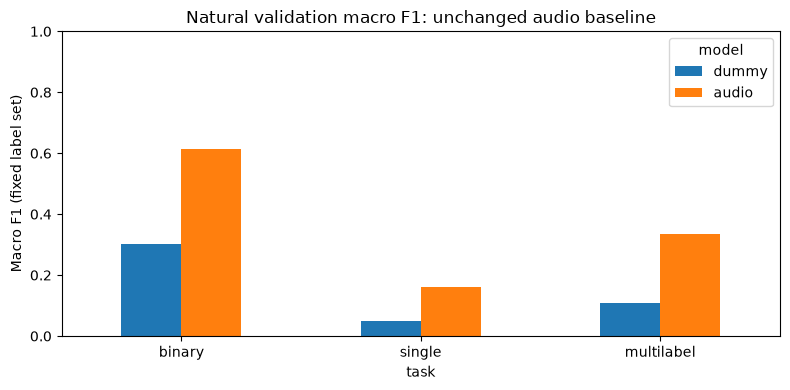

binary: audio macro F1=0.615, dummy=0.303; difference=+0.312 (higher), across 5 retained natural recording days.
single: audio macro F1=0.162, dummy=0.049; difference=+0.113 (higher), across 4 retained natural recording days.
multilabel: audio macro F1=0.335, dummy=0.110; difference=+0.225 (higher), across 4 retained natural recording days.
At most six validation days; sparse days/classes limit exploratory intervals. This is a redesigned protocol, not a direct comparison with the old pilot. Mono averaging and AIS proxy labels limit interpretation; reliability is not established. No test labels or audio were evaluated.


In [5]:
results = pd.DataFrame(scores)
print('Main benchmark: natural validation only; intervals are day-cluster percentiles.')
natural_results = results.loc[results['view'].eq('natural')]
display(natural_results.round(3))
print('Supplemental enriched coverage diagnostics, not pooled with natural validation.')
display(results.loc[results['view'].eq('coverage')].round(3))

comparison = natural_results.pivot(index='task', columns='model', values='macro_f1')
comparison = comparison.reindex(['binary', 'single', 'multilabel'])
comparison = comparison.reindex(columns=['dummy', 'audio'])
comparison['audio_minus_dummy'] = comparison['audio'] - comparison['dummy']
display(comparison.round(3))
comparison[['dummy', 'audio']].plot.bar(
    rot=0, ylim=(0, 1), figsize=(8, 4),
    title='Natural validation macro F1: unchanged audio baseline',
)
plt.ylabel('Macro F1 (fixed label set)')
plt.tight_layout()
plt.show()

# Describe current scores, not the old pilot or an assumed improvement.
for task, row in comparison.iterrows():
    if pd.isna(row['audio_minus_dummy']):
        print(f'{task}: insufficient usable natural validation for comparison.')
        continue
    task_days = natural_results.loc[natural_results['task'].eq(task), 'days'].max()
    direction = 'higher' if row['audio_minus_dummy'] > 0 else 'not higher'
    print(f'{task}: audio macro F1={row["audio"]:.3f}, dummy={row["dummy"]:.3f}; '
          f'difference={row["audio_minus_dummy"]:+.3f} ({direction}), '
          f'across {task_days} retained natural recording days.')
print('At most six validation days; sparse days/classes limit exploratory intervals. '
      'This is a redesigned protocol, not a direct comparison with the old pilot. '
      'Mono averaging and AIS proxy labels limit interpretation; reliability is not established. '
      'No test labels or audio were evaluated.')